# Process Trees from DMBD dataset

From LLNL page:

```
In addition to the ACME datasets, we also have the Dynamic Malware Behavior Dataset. This dataset is derived from 65,416 software samples with comprehensive execution logs. It can be used for training and evaluating machine learning models to distinguish between malicious and benign software based on their runtime behavior, with baseline accuracy of 95% that researchers are challenged to surpass.
```

* Data files can be found here: ```https://gdo168.llnl.gov/data/dmbd/```
* There are 8 large files with the data; pre-processing and extracting the required information is done in notebook ```clean_trees``` and saved in ```Data/all_trees.feather```
* only trees of size 3+ are retained


In [8]:
import pandas as pd
import numpy as np
import igraph as ig
from collections import Counter
import matplotlib.pyplot as plt
import tqdm

## our matching algorithm
import sys
import os
sys.path.insert(0,os.path.abspath('../Matching'))
import igraph_io as igio
import fast_match as fm  ## fast version

from dmbd_util import *


# Build the process trees and EDA

Build edges ```parent --> guid```

Process names are all hashes

We'll use either the ```malicious``` or ```test``` label for our exepriments.


In [20]:
# Read the entire feather file (prepared from other notebook)
process_summary = pd.read_feather('Data/all_trees.feather')

# Display the first few rows
print(process_summary.head())


        guid     parent process_name               timestamp  image_loads  \
0  G10154306              P76293.exe                     NaT            0   
1   G4029480  G10154306   P71830.exe 2024-08-24 16:31:37.055            0   
2  G18232545   G4029480   P85969.exe 2024-08-24 16:31:37.241            0   
3   G3413406  G18232545    P4164.exe 2024-08-24 16:31:37.338            0   
4  G20155766   G3413406   P51509.exe 2024-08-24 16:31:37.399            0   

   file_ops  network_connects experiment  malicious  test  
0         0                 0         E0       True  True  
1         0                 0         E0       True  True  
2         0                 0         E0       True  True  
3         0                 0         E0       True  True  
4         0                 0         E0       True  True  


In [21]:
## we'll use those throughout
dct_label = dict(zip(process_summary.guid, process_summary.malicious))
dct_test = dict(zip(process_summary.guid, process_summary.test))
dct_processname = dict(zip(process_summary.guid, process_summary.process_name))


In [22]:
process_summary = process_summary[process_summary.parent != '']

In [23]:
%%time
Trees = extract_process_trees(process=process_summary, uid='guid', parent_uid='parent',
                              min_tree_size=3, max_tree_size=1000000)


CPU times: user 4.32 s, sys: 170 ms, total: 4.49 s
Wall time: 4.49 s


In [24]:
## for plotting - malicious nodes in red
Trees.graph.vs['label_color'] = 'black'
Trees.graph.vs['color'] = 'black'
for v in Trees.graph.vs:
    if dct_label.get(v['uid'],0)>0:
        v['label_color']='red'
        v['color']='red'

### EDA

In [26]:
len(Trees)

34097

In [ ]:
### ICI ###

In [12]:
## Trees
Trees = G.connected_components(mode="weak")
G.vs['tree'] = Trees.membership
print('largest trees:', Counter(G.vs['tree']).most_common(5))


largest trees: [(9828, 4529), (19944, 4529), (27953, 4529), (1781, 4528), (22794, 4066)]


In [13]:
## trees with malicious label(s)
## either all or no node are malicious in any given tree
_df = pd.DataFrame( np.array([Trees.graph.vs['tree'] , Trees.graph.vs['malicious']]).T,columns=['tree','malicious'])
print('mean number of malicious nodes:',Counter(_df.groupby(by='tree')['malicious'].mean().to_list()))
tree_is_malicious = np.array(_df.groupby(by='tree')['malicious'].sum().to_list())


mean number of malicious nodes: Counter({1.0: 24603, 0.0: 9495})


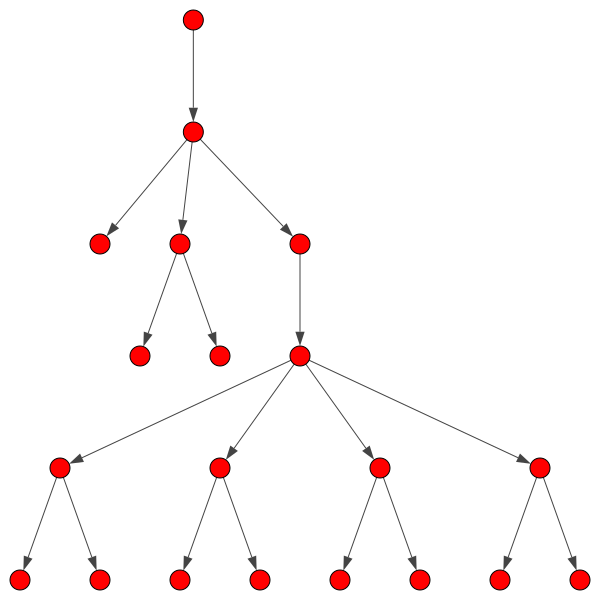

In [14]:
## example - malicious tree
idx = np.where( (np.array(Trees.sizes())==20) & (tree_is_malicious>0) )[0][0]
sg = Trees.subgraph(idx)
ly = sg.layout_reingold_tilford()
ig.plot(sg, layout=ly, vertex_label_size=0)


In [28]:
# Tree depth distribution
depths = np.empty(len(Trees), dtype="int64")
L = []
SG = Trees.subgraphs()
for tree_id in tqdm.trange(len(Trees)):
    tree = SG[tree_id]
    root = np.argmin(np.array(tree.degree(mode='in')))
    depth = max(tree.distances(root)[0]) # Trees are padded with extra start root
    depths[tree_id] = depth
    L.append([tree_id, tree.vcount(), sum(tree.vs['malicious']), depth, sum(tree.vs['test']) ])
G.vs['tree_depth'] = [depths[i] for i in G.vs['tree']]
_df = pd.DataFrame(L, columns=['tree','size','malicious','depth', 'test'])
_df['has_malicious'] = (_df['malicious']>0)
_df.head(5)


100%|██████████| 34098/34098 [00:00<00:00, 109938.86it/s]


,tree,size,malicious,depth,test,has_malicious
0,0,147,147,146,147,True
1,1,463,463,462,463,True
2,2,6,6,3,0,True
3,3,3,0,2,0,False
4,4,3,3,2,0,True


#### It turns out that tree depth is a strong feature to identify malicious trees ...


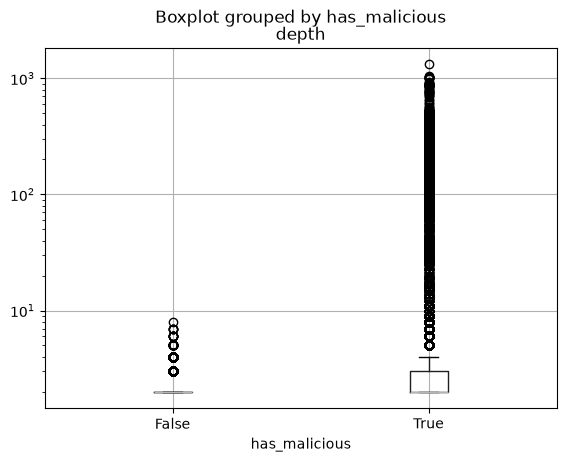

In [29]:
ax = _df.boxplot(column="depth", by="has_malicious", showfliers=True)
ax.set_yscale("log")


In [30]:
## most tree are shallow, a few are very deep
print('common depth:\n',Counter(depths).most_common(5))
print('deepest:',max(depths))
## max depth - non-malicious trees
print('deepest non-malicious:',max(_df[_df.has_malicious==False]['depth']))


common depth:
 [(np.int64(2), 24272), (np.int64(3), 3471), (np.int64(4), 1626), (np.int64(9), 638), (np.int64(5), 563)]
deepest: 1317
deepest non-malicious: 8


## Matching algorithm

In [31]:
## select trees of depth 3+
malicious_trees = list(_df[ (_df.depth>=3) & (_df.has_malicious) ]['tree'])
non_malicious_trees = list(_df[ (_df.depth>=3) & (_df.has_malicious == False) ]['tree'])
Trees.graph.vs['label_color'] = Trees.graph.vs['color']


In [33]:
%%time
Graphs = []
TreeData = []
nmt = 0

for i in malicious_trees:
    #sg = Trees.subgraph(i)
    sg = SG[i]
    if sg.vcount() == (sg.ecount()+1):
        Graphs.append(sg)
        TreeData.append(igio.igraph_to_treedata(sg, phi_name='process'))
        nmt += 1

for i in non_malicious_trees:
    #sg = Trees.subgraph(i)
    sg = SG[i]
    Graphs.append(sg)
    TreeData.append(igio.igraph_to_treedata(sg, phi_name='process'))

## encode all trees
fast = fm.FastTreePathMatcher()
fast.fit_encoder(TreeData)
enc = [fast.encode_tree(t) for t in TreeData]
       

CPU times: user 2.18 s, sys: 34 ms, total: 2.21 s
Wall time: 2.21 s


In [34]:
%%time
## compare all non-malicious tree with every malicious one (the templates)
Sim = np.zeros(shape=(nmt, len(non_malicious_trees)))
Paths = []
for i in range(nmt):
    for j in range(len(non_malicious_trees)):
        _, score = fast.predict_encoded(enc[i], enc[j+nmt])
        Sim[i,j] = score
Sim.shape
        

CPU times: user 1min 47s, sys: 44.7 ms, total: 1min 47s
Wall time: 1min 47s


(9200, 625)

In [35]:
## pick top similarity pair and visualize common path
(bad, nonbad) = np.unravel_index(np.argmax(Sim), Sim.shape)
sg1 = Graphs[bad]
sg2 = Graphs[nonbad+nmt]
_sg2 = igio.igraph_to_treedata(sg2, phi_name='process')
_sg1 = igio.igraph_to_treedata(sg1, phi_name='process')
fast = fm.FastTreePathMatcher()
fast.fit(_sg1,_sg2)
paths, score = fast.predict()

print('length of matching path:',score)


length of matching path: 6.0


number of nodes: 15


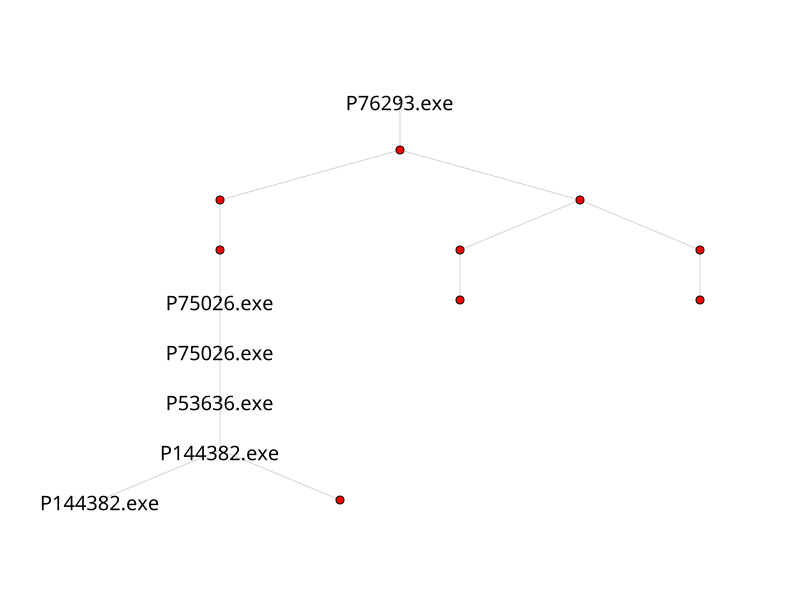

In [36]:
## plot malicious tree; highlight path
path = [int(x[0]) for x in paths]
sg1.vs['vertex_size'] = 8
sg1.vs['vertex_label_size'] = 1
for i in path:
    sg1.vs[i]['vertex_size'] = 1
    sg1.vs[i]['vertex_label_size'] = 20
print('number of nodes:',sg1.vcount())
ly = sg1.layout_reingold_tilford()
ig.plot(sg1, 
        bbox=(800,600), margin=100, layout=ly,
        vertex_size=sg1.vs['vertex_size'], 
        vertex_label=sg1.vs['process'], 
        vertex_label_size=sg1.vs['vertex_label_size'], 
        edge_color='lightgrey', edge_arrow_size=0)


number of nodes: 8


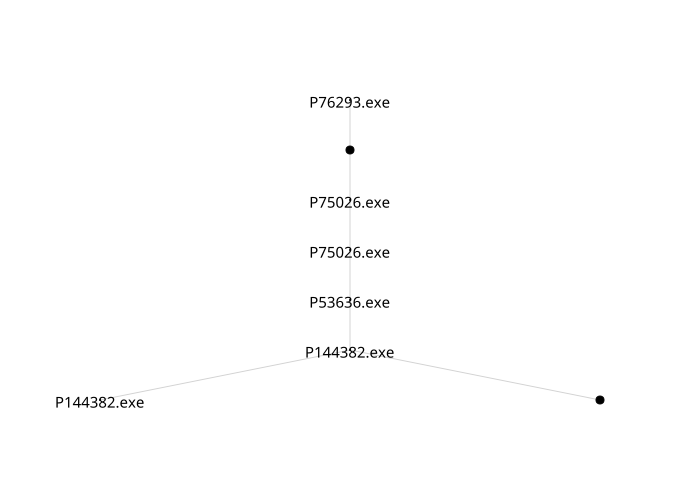

In [37]:
## plot matching non-malicious tree
path = [int(x[1]) for x in paths]
sg2.vs['vertex_size'] = 8
sg2.vs['vertex_label_size'] = 0
for i in path:
    sg2.vs[i]['vertex_size'] = 1
    sg2.vs[i]['vertex_label_size'] = 15
print('number of nodes:',sg2.vcount())
ly = sg2.layout_reingold_tilford()
ig.plot(sg2,
        bbox=(700,500), layout=ly, margin=100, 
        vertex_size=sg2.vs['vertex_size'], 
        vertex_label=sg2.vs['process'], 
        vertex_label_size=sg2.vs['vertex_label_size'], 
        edge_color='lightgrey', edge_arrow_size=0)


## Next we consider the "test" field


In [38]:
## select trees of depth 3+
train_trees = list(_df[ (_df.depth>=3) & (_df.test == 0) ]['tree'])
test_trees = list(_df[ (_df.depth>=3) & (_df.test > 0) ]['tree'])


In [39]:
%%time
Graphs = []
TreeData = []
n_train = 0
n_test = 0

for i in train_trees:
    #sg = Trees.subgraph(i)
    sg = SG[i]
    if sg.vcount() == (sg.ecount()+1):
        Graphs.append(sg)
        TreeData.append(igio.igraph_to_treedata(sg, phi_name='process'))
        n_train += 1

for i in test_trees:
    #sg = Trees.subgraph(i)
    sg = SG[i]
    if sg.vcount() == (sg.ecount()+1):
        Graphs.append(sg)
        TreeData.append(igio.igraph_to_treedata(sg, phi_name='process'))
        n_test += 1


CPU times: user 1.13 s, sys: 18 ms, total: 1.15 s
Wall time: 1.14 s


In [40]:
%%time
## encode all trees
fast = fm.FastTreePathMatcher()
fast.fit_encoder(TreeData)
enc = [fast.encode_tree(t) for t in TreeData]

## compare all 
Sim = np.zeros(shape=(n_train, n_test))
Paths = []
for i in range(n_train):
    for j in range(n_test):
        _, score = fast.predict_encoded(enc[i], enc[j+n_train])
        Sim[i,j] = score

Sim.shape


CPU times: user 14min 2s, sys: 205 ms, total: 14min 2s
Wall time: 14min 2s


(4964, 4861)

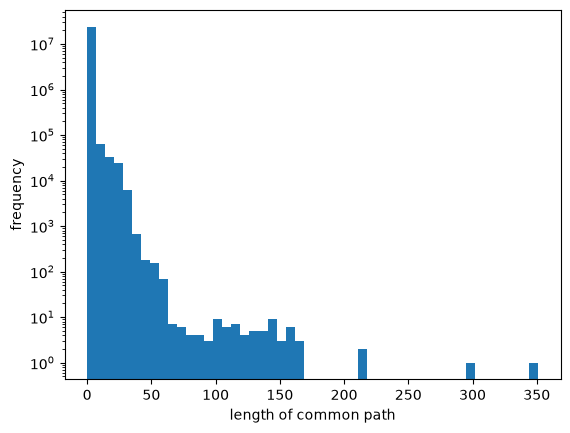

In [41]:
plt.hist(Sim.flatten(), log=True, bins=50)
plt.xlabel('length of common path')
plt.ylabel('frequency');


In [42]:
## pick top similarity pair and visualize common path
(bad, nonbad) = np.unravel_index(np.argmax(Sim), Sim.shape)
sg1 = Graphs[bad]
sg2 = Graphs[nonbad+n_train]
_sg2 = igio.igraph_to_treedata(sg2, phi_name='process')
_sg1 = igio.igraph_to_treedata(sg1, phi_name='process')
fast = fm.FastTreePathMatcher()
fast.fit(_sg1,_sg2)
paths, score = fast.predict()

print('length of matching path:',score)


length of matching path: 351.0


number of nodes: 1318


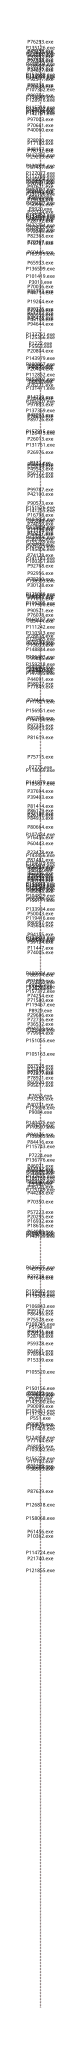

In [43]:
## plot tree with baduser ; highlight path
path = [int(x[0]) for x in paths]
sg1.vs['vertex_size'] = 1
sg1.vs['vertex_label_size'] = 1
for i in path:
    sg1.vs[i]['vertex_size'] = 1
    sg1.vs[i]['vertex_label_size'] = 12
print('number of nodes:',sg1.vcount())
ly = sg1.layout_reingold_tilford()
ig.plot(sg1, 
        bbox=(200,5000), margin=100, layout=ly,
        vertex_size=sg1.vs['vertex_size'], 
        vertex_label=sg1.vs['process'], 
        vertex_label_size=sg1.vs['vertex_label_size'], 
        edge_color='lightgrey', edge_arrow_size=0)


number of nodes: 999


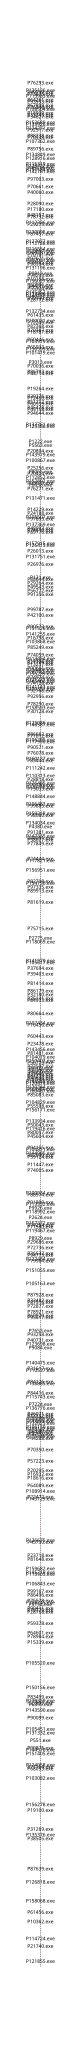

In [44]:
## plot top scoring tree
path = [int(x[1]) for x in paths]
sg2.vs['vertex_size'] = 1
sg2.vs['vertex_label_size'] = 0
for i in path:
    sg2.vs[i]['vertex_size'] = 1
    sg2.vs[i]['vertex_label_size'] = 12 
print('number of nodes:',sg2.vcount())
ly = sg2.layout_reingold_tilford()
ig.plot(sg2,
        bbox=(200,5000), layout=ly, margin=200, 
        vertex_size=sg2.vs['vertex_size'], 
        vertex_label=sg2.vs['process'], 
        vertex_label_size=sg2.vs['vertex_label_size'], 
        edge_color='lightgrey', edge_arrow_size=0)


### quick performance test - vary the number of comparisons exponentially
 

In [92]:
import time
_X = []
_Y = []
for N in [int(np.round(np.sqrt(2**i))) for i in np.arange(11,18)]: ## 25
          
    Graphs = []
    TreeData = []
    n_train = 0
    n_test = 0

    for i in train_trees[:N]:
        
        #sg = Trees.subgraph(i)
        sg = SG[i]
        if sg.vcount() == (sg.ecount()+1):
            Graphs.append(sg)
            TreeData.append(igio.igraph_to_treedata(sg, phi_name='process'))
            n_train += 1

    for i in test_trees[:N]:
        #sg = Trees.subgraph(i)
        sg = SG[i]
        if sg.vcount() == (sg.ecount()+1):
            Graphs.append(sg)
            TreeData.append(igio.igraph_to_treedata(sg, phi_name='process'))
            n_test += 1

    ## encode all trees
    fast = fm.FastTreePathMatcher()
    fast.fit_encoder(TreeData)
    enc = [fast.encode_tree(t) for t in TreeData]

    ## compare all high scoring with every template
    Sim = np.zeros(shape=(n_train, n_test))
    Paths = []
    before = time.time()    
    for i in range(n_train):
        for j in range(n_test):
            _, score = fast.predict_encoded(enc[i], enc[j+n_train])
            Sim[i,j] = score
    _X.append(N*N)
    _Y.append(time.time()-before)


In [101]:
B.predict(TreeData[0],TreeData[1])

([(0, 0)], 1.0)

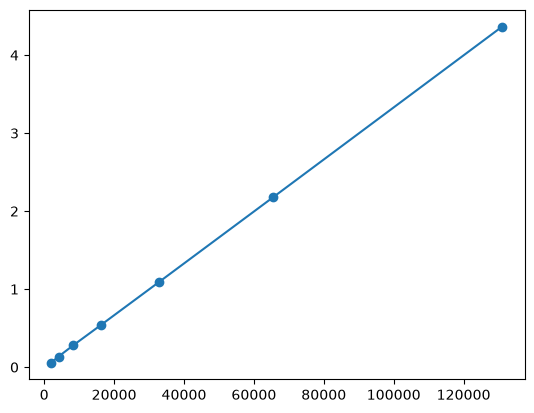

In [46]:
plt.plot(_X,_Y,'o-');

## Classification with random templates


In [62]:
min_depth = 3
n_template = 128
train_trees = list(_df[ (_df.depth>=min_depth) & (_df.test == 0) ]['tree'])
test_trees = list(_df[ (_df.depth>=min_depth) & (_df.test > 0) ]['tree'])
templates = np.random.choice(train_trees, n_template, replace=False)
train_trees = list(set(train_trees).difference(set(templates)))


In [63]:
Graphs = []
TreeData = []
n_templates = 0
n_train = 0
n_test = 0

drop = []

for i in templates:
    #sg = Trees.subgraph(i)
    sg = SG[i]
    if sg.vcount() == (sg.ecount()+1):
        Graphs.append(sg)
        TreeData.append(igio.igraph_to_treedata(sg, phi_name='process'))
        n_templates += 1
    else:
        drop.append(i)
        
for i in train_trees:
    #sg = Trees.subgraph(i)
    sg = SG[i]
    if sg.vcount() == (sg.ecount()+1):
        Graphs.append(sg)
        TreeData.append(igio.igraph_to_treedata(sg, phi_name='process'))
        n_train += 1
    else:
        drop.append(i)
        
for i in test_trees:
    #sg = Trees.subgraph(i)
    sg = SG[i]
    if sg.vcount() == (sg.ecount()+1):
        Graphs.append(sg)
        TreeData.append(igio.igraph_to_treedata(sg, phi_name='process'))
        n_test += 1
    else:
        drop.append(i)


In [64]:
## encode all trees
fast = fm.FastTreePathMatcher()
fast.fit_encoder(TreeData)
enc = [fast.encode_tree(t) for t in TreeData]


In [65]:
## compare all 
Sim = np.zeros(shape=(n_templates, n_train+n_test))
Paths = []
for i in range(n_templates):
    for j in range(n_train):
        _, score = fast.predict_encoded(enc[i], enc[j+n_templates])
        Sim[i,j] = score
    for j in range(n_test):
        _, score = fast.predict_encoded(enc[i], enc[j+n_templates+n_train])
        Sim[i,j+n_train] = score
Sim.shape


(128, 9697)

In [66]:
X = Sim.T.tolist()

X_train = X[:n_train]
X_test = X[n_train:(n_train+n_test)]

tree_label = dict(zip(_df.tree,_df.has_malicious))
y_train = [tree_label[i] for i in train_trees if i not in drop]
y_test = [tree_label[i] for i in test_trees if i not in drop]


In [67]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_jobs=16, random_state=123)
rf.fit(X_train, y_train)


,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",16
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",123
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the tota

In [68]:
from sklearn.metrics import roc_curve, auc

y_pred_proba = rf.predict_proba(X_test)[:,1]
fpr1, tpr1, thresholds1 = roc_curve(y_test, y_pred_proba)
print('AUC:',auc(fpr1, tpr1))

# plt.plot(fpr, tpr, label='ROC Curve')
# plt.xlabel('False Positive Rate')
# plt.ylabel('True Positive Rate')
# plt.title('Receiver Operating Characteristic (ROC) Curve')
# plt.legend()
# plt.grid()
# plt.show()


AUC: 0.9424841883965798


## classification - chosen templates from training set

In [69]:
min_depth = 3
train_trees = list(_df[ (_df.depth>=min_depth) & (_df.test == 0) ]['tree'])
test_trees = list(_df[ (_df.depth>=min_depth) & (_df.test > 0) ]['tree'])
tree_label = dict(zip(_df.tree,_df.has_malicious))


In [70]:
## encode dataset and save labels
TreeData = []
labels = []

## training
n_train = 0
for i in train_trees:
    #sg = Trees.subgraph(i)
    sg = SG[i]
    if sg.vcount() == (sg.ecount()+1):
        TreeData.append(igio.igraph_to_treedata(sg, phi_name='process'))
        labels.append(tree_label[i])
        n_train += 1

## testing 
n_test = 0
for i in test_trees:
    #sg = Trees.subgraph(i)
    sg = SG[i]
    if sg.vcount() == (sg.ecount()+1):
        TreeData.append(igio.igraph_to_treedata(sg, phi_name='process'))
        labels.append(tree_label[i])
        n_test += 1

## encode all trees
fast = fm.FastTreePathMatcher()
fast.fit_encoder(TreeData)
enc = [fast.encode_tree(t) for t in TreeData]


In [71]:
## first batch
batch_size = 16
training = list(range(n_train))
templates = np.random.choice(training, batch_size, replace=False).tolist()
training = list(set(training).difference(set(templates)))


In [72]:
### ...
for _rep in range(7):
    ## compare all and add new batch
    Sim = np.zeros(shape=(len(templates), len(training))) 
    for i in range(len(templates)):
        for j in range(len(training)):
            _, score = fast.predict_encoded(enc[templates[i]], enc[training[j]])
            Sim[i,j] = score
    ## new batch
    new_batch = [training[i] for i in np.argsort(Sim.max(axis=0))[:batch_size]] ## could play here
    templates.extend(new_batch)
    training = list(set(training).difference(set(templates)))


In [73]:
Sim = np.zeros(shape=(len(templates), len(training))) 
for i in range(len(templates)):
    for j in range(len(training)):
        _, score = fast.predict_encoded(enc[templates[i]], enc[training[j]])
        Sim[i,j] = score
X_train = Sim.T.tolist()
y_train = [labels[i] for i in training]


In [74]:
rf = RandomForestClassifier(n_jobs=2, random_state=123)
rf.fit(X_train, y_train)


,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",123
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [75]:
Sim = np.zeros(shape=(len(templates), n_test)) 
for i in range(len(templates)):
    for j in range(n_test):
        _, score = fast.predict_encoded(enc[templates[i]], enc[n_train+j])
        Sim[i,j] = score
X_test = Sim.T.tolist()
y_test = labels[n_train:]


In [76]:
y_pred_proba = rf.predict_proba(X_test)[:,1]
fpr2, tpr2, thresholds2 = roc_curve(y_test, y_pred_proba)
print('AUC:',auc(fpr2, tpr2))



AUC: 0.9424841883965798


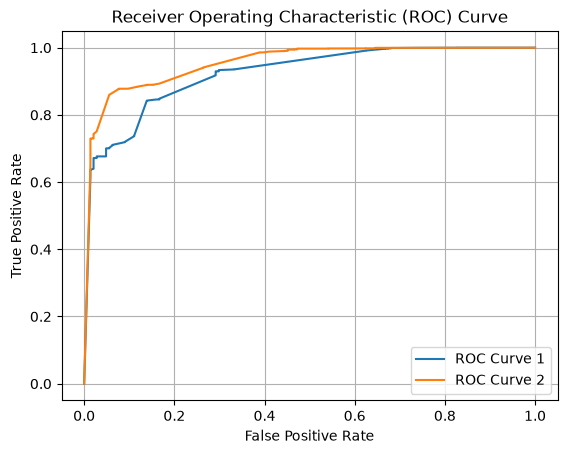

In [78]:
plt.plot(fpr1, tpr1, label='ROC Curve 1')
plt.plot(fpr2, tpr2, label='ROC Curve 2')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend()
plt.grid()
plt.show()
